## EDA: Entendimiento y calidad (P2)

Se lee la data OCDS (2023-2025) desde `data/raw/`, se pasa a `data/bronze/` (Parquet anidado) y se aplana a un modelo
**relacional** en `data/staging/<tabla>/`

### Imports

In [1]:
import os, socket, time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.sql.types import ArrayType, StructType

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)

### Utilidades

- Constantes

In [2]:
NOTEBOOK = "a_entendimiento"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

raw_dir     = proyecto / "data" / "raw"
bronze_dir  = proyecto / "data" / "bronze"
staging_dir = proyecto / "data" / "staging"
final_dir   = proyecto / "data" / "final"
artef_dir   = proyecto / "data" / "artefactos"
tc_path     = proyecto / "data" / "cambios.csv"
anios = [2023, 2024, 2025]

out_dir = proyecto / "01_EDA_KDD" / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
SHUFFLE = int(spark.conf.get("spark.sql.shuffle.partitions"))

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()

print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### 1. Entendimiento del problema

Las técnicas del P2 (clustering de actores, recomendación,
PageRank/HITS, comunidades, embeddings) trabajan sobre **relaciones**: quién compra a quién, quién compite con quién y en
qué rubro. El grano pasa a ser **entidad–proveedor–ítem**, y se necesita:

- **Identificadores** de compradores y proveedores, no solo nombres (el P1 solo guardó nombres)
- **Todos** los proveedores de **todas** las adjudicaciones (el P1 tomaba el primero): los consorcios son aristas
- Los **oferentes** (`tender.tenderers`) para el grafo de co-participación
- Los **contratos**, para decidir si la arista se define por adjudicación o por contrato

### 2. Preguntas de interés (detalle en `c_justificacion`)

- **PQ1 -> Concentración y cautividad:** ¿qué entidades dependen de pocos proveedores y qué proveedores concentran el
  gasto de muchas entidades?
- **PQ2 -> Mercados y grupos de competencia:** ¿qué mercados emergen de la co-participación? ¿Son regionales o por rubro?
  ¿Qué grupos de proveedores compiten siempre entre sí? (señal descriptiva, no acusación)
- **PQ3 -> Sustitutos y afinidades inusuales:** para una entidad, ¿qué proveedores son sustitutos según entidades
  parecidas, y qué relaciones entidad–proveedor son atípicas?

### 3. Carga de datos

#### a. Auxiliares

In [5]:
def rutas(schema, pre=""):
    out = []
    for f in schema.fields:
        out.append(pre + f.name)
        t = f.dataType.elementType if isinstance(f.dataType, ArrayType) else f.dataType
        if isinstance(t, StructType):
            out += rutas(t, pre + f.name + ".")
    return out

def fecha(c):
    return F.to_timestamp(F.substring(c.cast("string"), 1, 19), "yyyy-MM-dd'T'HH:mm:ss")

def listar_archivos(data, anios):
    archivos = []
    for a in anios:
        archivos += sorted((data / str(a)).glob("*.json"), key=lambda p: (len(p.stem), p.stem))
    return archivos

def leer_json(spark, archivos):
    return spark.read.option("multiLine", "true").option("mode", "PERMISSIVE").json([str(a) for a in archivos])

def extraer_releases(raw):
    # El envoltorio OCDS puede venir de 3 formas: se detecta en vez de asumirlo
    top = {c.lower() for c in raw.columns}
    if "releases" in top:
        return raw.select(F.explode("releases").alias("r")).select("r.*")
    elif "records" in top:
        rec = raw.select(F.explode("records").alias("x"))
        return (rec.select("x.compiledRelease.*") if "compiledRelease" in rec.select("x.*").columns
                else rec.select(F.explode("x.releases").alias("r")).select("r.*"))
    return raw

def sin_documentos(c):
    # los documentos son el objeto más numeroso del OCDS y no se usan: se descartan antes de escribir bronze
    if c == "tender":
        return F.col("tender").dropFields("documents").alias("tender")
    if c in ("awards", "contracts"):
        return F.transform(c, lambda x: x.dropFields("documents")).alias(c)
    return F.col(c)

#### b. Lectura y capa bronze

In [6]:
archivos = listar_archivos(raw_dir, anios)
MB_JSON = sum(a.stat().st_size for a in archivos) / 1024**2
rel = extraer_releases(leer_json(spark, archivos))

campos = [c for c in ["ocid", "date", "buyer", "tender", "awards", "contracts", "parties"] if c in rel.columns]
(rel.select(*[sin_documentos(c) for c in campos], F.input_file_name().alias("_archivo"))
    .write.mode("overwrite").parquet(str(bronze_dir)))

bronze = spark.read.parquet(str(bronze_dir))
RUTAS = {r.lower() for r in rutas(bronze.schema)}
existe = lambda p: p.lower() in RUTAS
mb_bronze = sum(f.stat().st_size for f in bronze_dir.rglob("*.parquet")) / 1024**2
print(f"{len(archivos)} archivos | JSON {MB_JSON:,.0f} MB -> bronze {mb_bronze:,.0f} MB")
print("¿tender.tenderers?", existe("tender.tenderers"), "| ¿contracts?", existe("contracts"))

36 archivos | JSON 3,864 MB -> bronze 264 MB
¿tender.tenderers? True | ¿contracts? True


- **Por qué una capa bronze:** parsear el JSON multilínea es el paso más caro (en el P1, 3.8 GB → 53 MB). Bronze conserva
  la estructura anidada en Parquet, y cada tabla siguiente lee solo las columnas que usa (*nested schema pruning*) sin
  volver a parsear el JSON
- Los `documents` se descartan: son millones de objetos que ninguna técnica usa

#### c. Vista relacional

In [7]:
def col(p, tipo="string"):
    return F.col(p).cast(tipo) if existe(p) else F.lit(None).cast(tipo)

def sub(alias, padre, campo, tipo="string"):
    # campo de un elemento ya explotado (alias.campo), validando la ruta absoluta padre.campo
    return F.col(f"{alias}.{campo}").cast(tipo) if existe(f"{padre}.{campo}") else F.lit(None).cast(tipo)

def explotar(ruta, alias):
    if existe(ruta):
        return bronze.select("ocid", F.explode(ruta).alias(alias))
    print(f"aviso: {ruta} no existe en el esquema -> tabla vacía")
    return bronze.select("ocid", F.lit(None).alias(alias)).where("false")

In [8]:
# --- procesos: 1 fila por ocid (como el staging del P1, ahora con identificador de entidad)
region_buyer = (F.expr("element_at(filter(transform(parties, p -> CASE WHEN array_contains(p.roles,'buyer') "
                       "THEN p.address.region END), x -> x IS NOT NULL), 1)")
                if existe("parties.address.region") else F.lit(None).cast("string"))

procesos = (bronze.select(
        "ocid",
        F.coalesce(fecha(col("tender.tenderPeriod.startDate")),
                   fecha(F.element_at(col("awards.date", "array<string>"), 1)),
                   fecha(col("date"))).alias("fecha"),
        F.coalesce(col("buyer.id"), col("tender.procuringEntity.id")).alias("entidad_id_raw"),
        F.coalesce(col("tender.procuringEntity.name"), col("buyer.name")).alias("entidad"),
        region_buyer.alias("region"),
        col("tender.description").alias("descripcion"),
        F.concat_ws(" ", col("tender.items.description", "array<string>")).alias("items_desc"),
        col("tender.procurementMethodDetails").alias("metodo_detalle"),
        col("tender.mainProcurementCategory").alias("categoria"),
        col("tender.value.amount", "double").alias("monto_referencial"),
        col("tender.value.currency").alias("moneda"),
        col("tender.numberOfTenderers", "int").alias("n_postores"),
        F.regexp_extract("_archivo", r"/(\d{4})/[^/]+\.json$", 1).cast("int").alias("anio_carpeta"))
    .withColumn("anio", F.coalesce(F.year("fecha"), F.col("anio_carpeta"))).drop("anio_carpeta"))

# --- adjudicaciones: 1 fila por (award, proveedor); los consorcios generan varias filas
aw = explotar("awards", "a").select(
    "ocid",
    sub("a", "awards", "id").alias("award_id"),
    fecha(sub("a", "awards", "date")).alias("fecha_adj"),
    sub("a", "awards", "status").alias("estado_adj"),
    sub("a", "awards", "value.amount", "double").alias("monto_adj"),
    sub("a", "awards", "value.currency").alias("moneda_adj"),
    sub("a", "awards", "items.classification.id", "array<string>").alias("unspsc_adj"),
    (F.col("a.suppliers") if existe("awards.suppliers")
     else F.lit(None).cast("array<struct<id:string,name:string>>")).alias("sup"))
adjudicaciones = (aw
    .withColumn("n_proveedores_adj", F.when(F.col("sup").isNull(), 0).otherwise(F.size("sup")))
    .select("*", F.explode_outer("sup").alias("s")).drop("sup")
    .select("*", sub("s", "awards.suppliers", "id").alias("proveedor_id_raw"),
                 sub("s", "awards.suppliers", "name").alias("proveedor")).drop("s"))

# --- oferentes: 1 fila por (proceso, oferente listado)
oferentes = explotar("tender.tenderers", "t").select(
    "ocid",
    sub("t", "tender.tenderers", "id").alias("oferente_id_raw"),
    sub("t", "tender.tenderers", "name").alias("oferente"))

# --- ítems del tender con su código UNSPSC (misma lógica del P1, ahora a nivel ítem)
unspsc_adicional = (F.expr("element_at(filter(coalesce(i.additionalClassifications, array()), "
                           "c -> upper(c.scheme) = 'UNSPSC'), 1).id")
                    if existe("tender.items.additionalClassifications.id") else F.lit(None))
items = explotar("tender.items", "i").select(
    "ocid",
    sub("i", "tender.items", "id").alias("item_id"),
    sub("i", "tender.items", "description").alias("item_desc"),
    sub("i", "tender.items", "quantity", "double").alias("cantidad"),
    F.coalesce(unspsc_adicional.cast("string"),
               F.when(F.upper(sub("i", "tender.items", "classification.scheme")) == "UNSPSC",
                      sub("i", "tender.items", "classification.id"))).alias("unspsc"))

# --- contratos: para medir el vínculo adjudicación <-> contrato
contratos = explotar("contracts", "c").select(
    "ocid",
    sub("c", "contracts", "id").alias("contrato_id"),
    sub("c", "contracts", "awardID").alias("award_id"),
    sub("c", "contracts", "status").alias("estado_contrato"),
    sub("c", "contracts", "value.amount", "double").alias("monto_contrato"),
    sub("c", "contracts", "value.currency").alias("moneda_contrato"),
    fecha(sub("c", "contracts", "dateSigned")).alias("fecha_firma"))

# --- partes: catálogo de identificadores/nombres/roles (base de la resolución de entidades)
partes = explotar("parties", "p").select(
    "ocid",
    sub("p", "parties", "id").alias("parte_id_raw"),
    sub("p", "parties", "name").alias("nombre"),
    sub("p", "parties", "identifier.id").alias("identificador"),
    sub("p", "parties", "identifier.scheme").alias("esquema"),
    sub("p", "parties", "roles", "array<string>").alias("roles"),
    sub("p", "parties", "address.region").alias("region"))

In [9]:
tablas_staging = {"procesos": procesos, "adjudicaciones": adjudicaciones, "oferentes": oferentes,
                  "items": items, "contratos": contratos, "partes": partes}

procesos.write.mode("overwrite").partitionBy("anio").parquet(str(staging_dir / "procesos"))
anio_ocid = F.broadcast(leer(staging_dir, "procesos").select("ocid", "anio"))
for nombre, df in tablas_staging.items():
    if nombre != "procesos":
        (df.join(anio_ocid, "ocid", "left")
           .write.mode("overwrite").partitionBy("anio").parquet(str(staging_dir / nombre)))

st = {n: leer(staging_dir, n) for n in tablas_staging}

- Todas las tablas se particionan por `anio`: un filtro por año poda carpetas en **todas** (no solo en procesos)
- El año viene de `procesos` con un *broadcast join* (los pares `ocid`/`anio` caben en memoria de cada executor), lo que
  evita un shuffle de la tabla grande

#### d. Volumen

In [10]:
conteos = pd.DataFrame([(n, df.count(), df.select("ocid").distinct().count()) for n, df in st.items()],
                       columns=["tabla", "filas", "ocid_distintos"])
conteos["filas_por_ocid"] = (conteos.filas / conteos.ocid_distintos.clip(lower=1)).round(2)
conteos["mb_parquet"] = [round(sum(f.stat().st_size for f in (staging_dir / n).rglob("*.parquet")) / 1024**2, 1)
                         for n in conteos.tabla]
conteos

,tabla,filas,ocid_distintos,filas_por_ocid,mb_parquet
0,procesos,236254,236254,1.00,46.3
1,adjudicaciones,203522,185002,1.10,10.5
2,oferentes,2907635,215077,13.52,50.8
3,items,280445,236226,1.19,23.6
4,contratos,196932,171804,1.15,6.2
5,partes,3143894,236254,13.31,69.4


- ‹filas_por_ocid de adjudicaciones› proveedores adjudicados por proceso y ‹de oferentes› oferentes listados: es la
  multiplicidad que el P1 colapsaba a 1
- Si `oferentes` sale vacía, el grafo de co-participación se reemplaza por la proyección o un grafo KNN (`KDD/b_artefactos`)

### 4. Descripción de tablas

| Tabla | Grano | Columnas clave | Uso en el P2 |
|---|---|---|---|
| `procesos` | ocid | `entidad_id_raw`, `region`, `metodo_detalle`, `categoria`, `n_postores`, `monto_referencial` | Atributos del proceso y features de entidad |
| `adjudicaciones` | award × proveedor | `award_id`, `estado_adj`, `monto_adj`, `proveedor_id_raw`, `n_proveedores_adj`, `unspsc_adj` | Aristas entidad–proveedor y matriz de interacción |
| `oferentes` | proceso × oferente | `oferente_id_raw`, `oferente` | Grafo de co-participación y tasa de éxito |
| `items` | ítem del tender | `unspsc` | Rubro/familia (grano ítem) |
| `contratos` | contrato | `award_id`, `monto_contrato` | Decidir el criterio de arista |
| `partes` | parte × proceso | `parte_id_raw`, `identificador`, `roles`, `region` | Resolución de entidades y región del proveedor |

### 5. Calidad de datos

#### a. Nulos en llaves

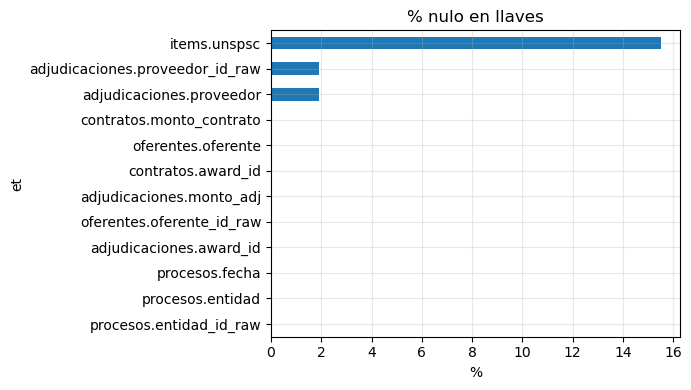

In [11]:
llaves = {"procesos": ["entidad_id_raw", "entidad", "fecha"],
          "adjudicaciones": ["award_id", "proveedor_id_raw", "proveedor", "monto_adj"],
          "oferentes": ["oferente_id_raw", "oferente"],
          "items": ["unspsc"],
          "contratos": ["award_id", "monto_contrato"]}
vacio = lambda c: (F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == "")).cast("int")
filas = []
for t, cols in llaves.items():
    r = st[t].agg(F.count("*").alias("_n"), *[F.sum(vacio(c)).alias(c) for c in cols]).first()
    filas += [(t, c, round(100 * (r[c] or 0) / max(r["_n"], 1), 1)) for c in cols]
nulos = pd.DataFrame(filas, columns=["tabla", "columna", "pct_nulo"])

nulos.assign(et=nulos.tabla + "." + nulos.columna).set_index("et").pct_nulo.sort_values().plot.barh(figsize=(7, 4))
plt.title("% nulo en llaves"); plt.xlabel("%")
mostrar_fig("nulos_llaves")

#### b. Formato de identificadores

In [12]:
def patron(c):
    return (F.when(F.col(c).isNull(), "nulo")
             .when(F.col(c).rlike(r"RUC\D?\d{11}$"), "RUC con prefijo")
             .when(F.col(c).rlike(r"^\d{11}$"), "11 digitos")
             .when(F.col(c).rlike(r"(?<!\d)\d{8}$"), "8 digitos (DNI)")
             .otherwise("otro"))

formatos = (st["adjudicaciones"].select(patron("proveedor_id_raw").alias("formato"), F.lit("proveedor").alias("rol"))
    .unionByName(st["oferentes"].select(patron("oferente_id_raw").alias("formato"), F.lit("oferente").alias("rol")))
    .unionByName(st["procesos"].select(patron("entidad_id_raw").alias("formato"), F.lit("entidad").alias("rol")))
    .groupBy("rol", "formato").count().orderBy("rol", F.desc("count")))
formatos.show(truncate=False)
st["adjudicaciones"].where(patron("proveedor_id_raw") == "otro").select("proveedor_id_raw", "proveedor").show(5, truncate=60)

+---------+---------------+-------+
|rol      |formato        |count  |
+---------+---------------+-------+
|entidad  |otro           |236254 |
|oferente |RUC con prefijo|2756666|
|oferente |otro           |150969 |
|proveedor|RUC con prefijo|152962 |
|proveedor|otro           |46643  |
|proveedor|nulo           |3917   |
+---------+---------------+-------+

+----------------+--------------------------+
|proveedor_id_raw|                 proveedor|
+----------------+--------------------------+
|  PE-RUC-1754638|      CONSORCIO YANACCOCHA|
|  PE-RUC-1761092|          CONSORCIO RIVAEZ|
|  PE-RUC-1765876|        CONSORCIO PULPERIA|
|  PE-RUC-1797308|        CONSORCIO SAN JUAN|
|  PE-RUC-1763837|CONSORCIO SJ  SUPERVISORES|
+----------------+--------------------------+
only showing top 5 rows



#### c. Identificadores duplicados (advertencia de la fuente)

In [13]:
dup_mismo_id = st["oferentes"].groupBy("ocid", "oferente_id_raw").count().where("count > 1")
dup_mismo_nombre = (st["oferentes"].groupBy("ocid", F.upper(F.trim("oferente")).alias("nom"))
                    .agg(F.countDistinct("oferente_id_raw").alias("ids")).where("ids > 1"))
nombres_por_id = (st["adjudicaciones"].groupBy("proveedor_id_raw")
                  .agg(F.countDistinct(F.upper(F.trim("proveedor"))).alias("nombres"),
                       F.collect_set("proveedor").alias("variantes")).where("nombres > 1"))
ids_por_nombre = (st["adjudicaciones"].groupBy(F.upper(F.trim("proveedor")).alias("nombre"))
                  .agg(F.countDistinct("proveedor_id_raw").alias("ids")).where("ids > 1"))

duplicados = pd.DataFrame([
    ("oferente repetido con el mismo id en un proceso", dup_mismo_id.count()),
    ("mismo nombre con ids distintos en un proceso", dup_mismo_nombre.count()),
    ("id de proveedor con varios nombres", nombres_por_id.count()),
    ("nombre de proveedor con varios ids", ids_por_nombre.count())], columns=["caso", "n"])
display(duplicados)
nombres_por_id.orderBy(F.desc("nombres")).show(5, truncate=80)

,caso,n
0,oferente repetido con el mismo id en un proceso,0
1,mismo nombre con ids distintos en un proceso,2779
2,id de proveedor con varios nombres,234
3,nombre de proveedor con varios ids,5727


+------------------+-------+--------------------------------------------------------------------------------+
|  proveedor_id_raw|nombres|                                                                       variantes|
+------------------+-------+--------------------------------------------------------------------------------+
|PE-RUC-20229677200|      3|[EMPRESA DE SERVICIOS DE TRANSPORTE DE CARGA PESADA LUZ DE LUNA E.I.R.L., EMP...|
|PE-RUC-20534355646|      3|[EMPRESA CONSTRUCTORA Y SERVICIOS IPERSAN E.I.R.L., EMPRESA CONSTRUCTORA Y SE...|
|PE-RUC-20571170958|      3|[CORPORACION INTERNACIONAL GRUPO TOPCONSA S.A.C. - GRUPO TOPCONSA S.A.C., CON...|
|PE-RUC-20552504641|      3|             [OPTICAL TECHNOLOGIES SAC, ON EMPRESAS S.A.C., WIN EMPRESAS S.A.C.]|
|PE-RUC-20100148162|      2|            [CIA DE SEGURIDAD PROSEGUR S A, COMPAÑIA DE SEGURIDAD PROSEGUR S. A]|
+------------------+-------+--------------------------------------------------------------------------------+
only showi

#### d. Vínculo adjudicación ↔ contrato

In [14]:
adj_u = st["adjudicaciones"].select("ocid", "award_id").distinct()
con_u = st["contratos"].select("ocid", "award_id").distinct()
n_adj, n_con = adj_u.count(), con_u.count()
adj_sin = adj_u.join(con_u, ["ocid", "award_id"], "left_anti").count()
con_sin = con_u.join(adj_u, ["ocid", "award_id"], "left_anti").count()
vinculo = pd.DataFrame([("adjudicaciones", n_adj, adj_sin, round(100 * adj_sin / max(n_adj, 1), 1)),
                        ("contratos", n_con, con_sin, round(100 * con_sin / max(n_con, 1), 1))],
                       columns=["objeto", "total", "sin_contraparte", "pct"])
vinculo

,objeto,total,sin_contraparte,pct
0,adjudicaciones,203522,21853,10.7
1,contratos,183443,1774,1.0


#### e. Estados de adjudicación y consorcios

In [15]:
estados = (st["adjudicaciones"].groupBy("estado_adj")
           .agg(F.countDistinct("ocid", "award_id").alias("awards")).orderBy(F.desc("awards")))
estados.show()
consorcios = (st["adjudicaciones"].select("ocid", "award_id", "n_proveedores_adj").distinct()
              .groupBy("n_proveedores_adj").count().orderBy("n_proveedores_adj"))
consorcios.show(6)
print("proveedores cuyo nombre empieza con CONSORCIO:",
      st["adjudicaciones"].where(F.upper("proveedor").startswith("CONSORCIO")).select("proveedor_id_raw").distinct().count())

+----------+------+
|estado_adj|awards|
+----------+------+
|      NULL|203522|
+----------+------+

+-----------------+------+
|n_proveedores_adj| count|
+-----------------+------+
|                0|  3917|
|                1|199605|
+-----------------+------+

proveedores cuyo nombre empieza con CONSORCIO: 40297


#### Acciones previstas

| Problema | Acción (en `KDD/a_transformaciones`) | Por qué |
|---|---|---|
| Ids con formatos distintos / prefijos | Extraer RUC (11 dígitos) o DNI (8) → `clave` canónica | Un mismo RUC escrito distinto no debe dar dos nodos |
| RUC 10 = persona natural (10 + DNI + dígito) | `RUC 10XXXXXXXXd` y `DNI XXXXXXXX` → misma clave `PN:` | Es la misma persona con dos identificadores válidos |
| Oferentes duplicados dentro del proceso | `distinct (ocid, clave)` tras resolver | Si no, se infla el peso de co-participación |
| Menciones sin identificador | MinHash/LSH sobre nombres normalizados → enlazar a clave existente o crear nodo `NOM:` | Reutiliza el enfoque de similitud del P1 |
| Mismo nombre con RUC distinto | **No** se fusionan; se reportan como "posibles vinculadas" | RUC distinto = persona jurídica distinta |
| Adjudicación sin contrato (y viceversa) | Arista por **adjudicación**; contrato como atributo `tiene_contrato` | Usar contratos perdería ‹pct›% de relaciones |
| Award `cancelled` / `unsuccessful` | Se excluye de las aristas | No es una relación efectiva entidad–proveedor |
| Moneda ≠ PEN / monto ≤ 0 | Igual que en el P1 (BCRP / nulo) | Comparabilidad |

### 6. Escritura de resultados

Se guardan en `01_EDA_KDD/temp/a_entendimiento/tablas/` (parquet) y `web/` (json)

In [16]:
tablas = {"conteos_staging": conteos, "nulos_llaves": nulos, "formatos_id": formatos,
          "duplicados_id": duplicados, "vinculo_adj_contrato": vinculo, "estados_adj": estados,
          "consorcios": consorcios}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en 01_EDA_KDD/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 01_EDA_KDD/temp/a_entendimiento/: conteos_staging, nulos_llaves, formatos_id, duplicados_id, vinculo_adj_contrato, estados_adj, consorcios


#### a. Verificación

In [17]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"

figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 7 tablas (parquet + json) | 1 figuras: nulos_llaves


---
### 7. Cerrar sesión

In [18]:
spark.stop()